# Module 10: Natural Language Processing: hands-on lab

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/prajwalskandas31-sudo/ai-engineering-course/blob/main/module-10-nlp/Module_10_Lab.ipynb)

Part of the free **AI Engineering Course** by Tech with Prajwal. ▶️ [Module 10 videos](https://www.youtube.com/playlist?list=PLCpq4dWJGmXA) · 📒 [Study notes (Notion)](https://chipped-willow-4a2.notion.site/41e6f1ed006e8190a4b8f73406ae9a07) · 💻 [Module 10 on GitHub](https://github.com/prajwalskandas31-sudo/ai-engineering-course/tree/main/module-10-nlp)

**How to use:** run the cells from top to bottom (**Runtime → Run all**), or one at a time with **Shift + Enter**. Everything this lab needs is already installed in Google Colab. Change the numbers and re-run to experiment.

## nlp_lesson.py

Module 10: Natural Language Processing: Practical Lesson
From raw text to a sentiment classifier and a retrieval chatbot

  Part 1  Cleaning and tokenizing: lowercase, strip punctuation with a regex,
          split into tokens, remove stop words, and watch the vocabulary shrink.
  Part 2  Stemming vs lemmatization (NLTK): fast-but-crude vs slower-but-real-words.
  Part 3  Turning text into numbers: Bag of Words, bigrams, TF-IDF and cosine
          similarity.
  Part 4  A Naive Bayes sentiment classifier, including why bigrams catch "not good".
  Part 5  Lexicon sentiment scores with VADER (NLTK) and TextBlob.
  Part 6  A retrieval chatbot: greetings, TF-IDF + cosine-similarity answers,
          a fallback when it doesn't understand, and "bye".

Run:  python nlp_lesson.py
Needs: scikit-learn, numpy, matplotlib. Parts 2 and 5 also use nltk and textblob
(pip install nltk textblob); if they are missing those parts are skipped.
Everything runs in Google Colab.

In [ ]:
import random
import re
from collections import Counter
import numpy as np
import matplotlib
matplotlib.use("Agg")  # save the figure to a file; no window needed
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.naive_bayes import MultinomialNB
random.seed(42)

### `header()`

In [ ]:
def header(title):
    print("\n" + "=" * 70)
    print(title)
    print("=" * 70)

### `try_nltk()`: Import NLTK and fetch the small data packages it needs. Returns the module or None.

In [ ]:
def try_nltk():
    """Import NLTK and fetch the small data packages it needs. Returns the module or None."""
    try:
        import nltk
        for pkg in ["wordnet", "omw-1.4", "vader_lexicon", "stopwords"]:
            nltk.download(pkg, quiet=True)
        nltk.corpus.wordnet.synsets("test")          # raises if WordNet didn't download
        return nltk
    except Exception as e:                             # not installed, or no internet
        print(f"(NLTK not available here: {type(e).__name__}. Install with: pip install nltk)")
        return None

### THE DATA: short product and movie reviews, labelled 1 = positive, 0 = negative

In [ ]:
# =============================================================================
# THE DATA: short product and movie reviews, labelled 1 = positive, 0 = negative
# =============================================================================
REVIEWS = [
    ("Absolutely loved this phone, the battery lasts forever!", 1),
    ("Great value for money and the screen is stunning.", 1),
    ("The movie was fantastic, I enjoyed every minute.", 1),
    ("Brilliant acting and a wonderful story.", 1),
    ("Fast delivery and the quality is excellent.", 1),
    ("I am really happy with this purchase, works perfectly.", 1),
    ("Superb sound, comfortable to wear, highly recommend.", 1),
    ("The hotel staff were friendly and the room was clean.", 1),
    ("Good food, good service, we will come back.", 1),
    ("Easy to set up and the camera takes beautiful photos.", 1),
    ("Lovely design and it feels solid in the hand.", 1),
    ("Best laptop I have owned, fast and reliable.", 1),
    ("A heartwarming film with a great soundtrack.", 1),
    ("Exceeded my expectations, the keyboard is a joy to use.", 1),
    ("Terrible battery, it dies before lunch.", 0),
    ("The screen cracked in a week, very poor quality.", 0),
    ("Worst movie I have seen, boring and far too long.", 0),
    ("Awful acting and a confusing plot.", 0),
    ("Delivery was late and the box was damaged.", 0),
    ("I want a refund, it stopped working after two days.", 0),
    ("Uncomfortable, cheap plastic and the sound is tinny.", 0),
    ("The hotel room was dirty and the staff were rude.", 0),
    ("Cold food and slow service, never again.", 0),
    ("Hard to set up and the photos are blurry.", 0),
    ("Ugly design and it feels flimsy.", 0),
    ("Slow laptop that keeps crashing.", 0),
    ("A dull film with an annoying soundtrack.", 0),
    ("Not worth the money, very disappointing.", 0),
    # a few negations, so the model has a chance to learn phrases like "not good"
    ("Not good, the battery is weak.", 0),
    ("The food was not great and not fresh.", 0),
    ("I was not happy with the service.", 0),
    ("Honestly not bad, I liked it.", 1),
    ("Not bad for the price, it works well.", 1),
    ("Not disappointed at all, a good buy.", 1),
]
TEST_REVIEWS = [
    ("The camera is excellent and the battery is great.", 1),
    ("Friendly staff and a clean, lovely room.", 1),
    ("Boring story and terrible acting.", 0),
    ("It broke after a week, poor quality and a waste of money.", 0),
    ("This is not good at all.", 0),
    ("Not bad at all, I really enjoyed it.", 1),
]

### `clean()`

In [ ]:
# =============================================================================
# PART 1: CLEANING AND TOKENIZING
# =============================================================================
def clean(text):
    text = text.lower()                         # 'Data' and 'data' become the same word
    text = re.sub(r"[^\w\s]", "", text)         # strip punctuation and symbols
    return text

### `tokenize()`

In [ ]:
def tokenize(text):
    return re.findall(r"\b\w+\b", text)

### `remove_stopwords()`

In [ ]:
def remove_stopwords(tokens, stop_words):
    return [t for t in tokens if t not in stop_words]

### `part1_preprocessing()`

In [ ]:
def part1_preprocessing():
    header("PART 1: CLEANING AND TOKENIZING RAW TEXT")
    raw = "WOW!!! The battery LASTS forever... but the Screen? Not great, honestly :("
    cleaned = clean(raw)
    tokens = tokenize(cleaned)
    no_stop = remove_stopwords(tokens, ENGLISH_STOP_WORDS)
    print(f"Raw text:        {raw}")
    print(f"Lowercased and punctuation removed: '{cleaned}'")
    print(f"Tokens ({len(tokens)}):      {tokens}")
    print(f"After stop words ({len(no_stop)}): {no_stop}")
    print("Careful: 'not' is a stop word, so removing stop words throws away the negation!")

    # How much does preprocessing shrink the vocabulary across all reviews?
    texts = [t for t, _ in REVIEWS]
    raw_vocab = set(w for t in texts for w in t.split())
    clean_vocab = set(w for t in texts for w in tokenize(clean(t)))
    final_vocab = clean_vocab - ENGLISH_STOP_WORDS
    print(f"\nVocabulary across {len(texts)} reviews:")
    print(f"  split on spaces only:          {len(raw_vocab)} distinct 'words'")
    print(f"  lowercased, no punctuation:    {len(clean_vocab)}")
    print(f"  ...and no stop words:          {len(final_vocab)}")
    print("Fewer, cleaner dimensions = less sparsity for the model.")

### `part2_stemming_vs_lemmatization()`

In [ ]:
# =============================================================================
# PART 2: STEMMING VS LEMMATIZATION (NLTK)
# =============================================================================
def part2_stemming_vs_lemmatization(nltk):
    header("PART 2: STEMMING vs LEMMATIZATION")
    if nltk is None:
        print("Skipped: needs NLTK and its WordNet data (pip install nltk). It runs in Colab.")
        return
    from nltk.stem import PorterStemmer, LancasterStemmer, SnowballStemmer, WordNetLemmatizer
    porter, lancaster, snowball = PorterStemmer(), LancasterStemmer(), SnowballStemmer("english")
    lemma = WordNetLemmatizer()
    words = [("jumping", "v"), ("jumped", "v"), ("computing", "v"), ("studies", "n"),
             ("hobbies", "n"), ("better", "a"), ("running", "v"), ("geese", "n")]
    print(f"{'word':<11}{'Porter':<10}{'Lancaster':<11}{'Snowball':<10}{'Lemma (with POS)':<18}{'Lemma (no POS)'}")
    for w, pos in words:
        print(f"{w:<11}{porter.stem(w):<10}{lancaster.stem(w):<11}{snowball.stem(w):<10}"
              f"{lemma.lemmatize(w, pos=pos):<18}{lemma.lemmatize(w)}")
    print("\nStems can be non-words ('comput', 'hobbi'); lemmas are always real words,")
    print("but only if you give the part of speech: without pos='v', 'running' stays 'running'.")
    print("Rule of thumb: stem for fast classification, lemmatize for anything a user reads (chatbots).")

### PART 3: TEXT -> NUMBERS

In [ ]:
# =============================================================================
# PART 3: TEXT -> NUMBERS
# =============================================================================
DOCS = [
    "Data science uses statistics and data to find insights.",
    "Machine learning models learn patterns from data.",
    "Natural language processing turns text into numbers for machine learning.",
]

### `part3_vectorization()`

In [ ]:
def part3_vectorization():
    header("PART 3: BAG OF WORDS, BIGRAMS, TF-IDF AND COSINE SIMILARITY")
    bow = CountVectorizer(stop_words="english")
    X = bow.fit_transform(DOCS)
    vocab = bow.get_feature_names_out()
    print(f"Bag of Words: {X.shape[0]} documents x {X.shape[1]} words")
    print("  " + " ".join(f"{w[:9]:>9}" for w in vocab))
    for i, row in enumerate(X.toarray()):
        print(f"D{i + 1}" + "".join(f"{v:>10}" for v in row))
    print(f"Matrix is {(X.toarray() == 0).mean():.0%} zeros: text vectors are sparse.")

    bi = CountVectorizer(ngram_range=(1, 2), stop_words="english").fit(DOCS)
    bigrams = [t for t in bi.get_feature_names_out() if " " in t]
    print(f"\nAdding bigrams grows the vocabulary from {len(vocab)} to {len(bi.get_feature_names_out())}, e.g. {bigrams[:4]}")

    tfidf = TfidfVectorizer(stop_words="english")
    T = tfidf.fit_transform(DOCS)
    idf = dict(zip(tfidf.get_feature_names_out(), tfidf.idf_))
    print("\nIDF (higher = rarer = more informative):")
    for w in ["data", "learning", "statistics", "text"]:
        print(f"  {w:<11} idf = {idf[w]:.2f}   (in {sum(w in d.lower() for d in DOCS)} of {len(DOCS)} docs)")

    query = "how do machines learn from data"
    q = tfidf.transform([query])
    sims = cosine_similarity(q, T)[0]
    print(f"\nQuery: '{query}'")
    for i, s in enumerate(sims):
        print(f"  cosine similarity with D{i + 1}: {s:.3f}")
    print(f"Best match: D{sims.argmax() + 1}: \"{DOCS[sims.argmax()]}\"")
    return tfidf, T

### `part4_naive_bayes()`

In [ ]:
# =============================================================================
# PART 4: NAIVE BAYES SENTIMENT CLASSIFIER
# =============================================================================
def part4_naive_bayes():
    header("PART 4: NAIVE BAYES SENTIMENT CLASSIFIER")
    X_train = [clean(t) for t, _ in REVIEWS]
    y_train = [y for _, y in REVIEWS]
    X_test = [clean(t) for t, _ in TEST_REVIEWS]
    y_test = [y for _, y in TEST_REVIEWS]

    results = {}
    for name, ngrams in [("unigrams only", (1, 1)), ("unigrams + bigrams", (1, 2))]:
        vec = CountVectorizer(ngram_range=ngrams)
        nb = MultinomialNB(alpha=1.0)              # alpha=1 is Laplace (add-one) smoothing
        nb.fit(vec.fit_transform(X_train), y_train)
        preds = nb.predict(vec.transform(X_test))
        probs = nb.predict_proba(vec.transform(X_test))[:, 1]
        results[name] = (vec, nb, preds, probs)
        print(f"\nModel with {name}: {len(vec.vocabulary_)} features, "
              f"{(preds == np.array(y_test)).sum()}/{len(y_test)} test reviews correct")
        for (text, truth), p, pr in zip(TEST_REVIEWS, preds, probs):
            mark = "ok " if p == truth else "XX "
            print(f"  {mark} P(positive)={pr:.2f}  {'pos' if p else 'neg'}  \"{text}\"")

    vec, nb, _, _ = results["unigrams only"]
    print(f"\nPriors learned from the training data: P(pos)={np.exp(nb.class_log_prior_[1]):.2f}, "
          f"P(neg)={np.exp(nb.class_log_prior_[0]):.2f}")
    words = vec.get_feature_names_out()
    lean = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]   # log P(w|pos) - log P(w|neg)
    order = np.argsort(lean)
    print("Most positive words:", ", ".join(words[order[-8:]][::-1]))
    print("Most negative words:", ", ".join(words[order[:8]]))
    print("\nNotice 'bad' among the positive words: it only appears in 'not bad' reviews, so the model")
    print("learns the word without its context. Bigrams add 'not bad' and 'not good' as features of their own,")
    p_uni = results["unigrams only"][3][4]
    p_bi = results["unigrams + bigrams"][3][4]
    print(f"but with only {len(REVIEWS)} training reviews, 'This is not good at all' still comes out positive "
          f"(P={p_uni:.2f} -> {p_bi:.2f}):")
    print("common words like 'this' and 'at all' outvote a single 'not good' example. More data fixes that,")
    print("and so do sentiment lexicons that handle negation directly (Part 5).")
    return words, lean

### PART 5: LEXICON SENTIMENT (VADER AND TEXTBLOB)

In [ ]:
# =============================================================================
# PART 5: LEXICON SENTIMENT (VADER AND TEXTBLOB)
# =============================================================================
PHRASES = ["great", "very great", "not great", "GREAT!!!", "The service was terrible.",
           "The food was okay.", "Not bad at all :)"]

### `part5_lexicons()`

In [ ]:
def part5_lexicons(nltk):
    header("PART 5: LEXICON SENTIMENT SCORES (VADER AND TEXTBLOB)")
    scores = {}
    vader = None
    if nltk is not None:
        from nltk.sentiment.vader import SentimentIntensityAnalyzer
        vader = SentimentIntensityAnalyzer()
    try:
        from textblob import TextBlob
    except ImportError:
        TextBlob = None
    if vader is None and TextBlob is None:
        print("Skipped: needs nltk (VADER) and/or textblob (pip install nltk textblob). Both run in Colab.")
        return scores
    print(f"{'Text':<28}{'VADER compound':>16}{'TextBlob polarity':>19}{'subjectivity':>14}")
    for p in PHRASES:
        v = vader.polarity_scores(p)["compound"] if vader else float("nan")
        if TextBlob:
            s = TextBlob(p).sentiment
            tb, sub = s.polarity, s.subjectivity
        else:
            tb = sub = float("nan")
        scores[p] = (v, tb)
        print(f"{p:<28}{v:>16.3f}{tb:>19.2f}{sub:>14.2f}")
    print("\nVADER: compound >= 0.05 is positive, <= -0.05 negative, otherwise neutral.")
    print("Both handle 'very' (boost) and 'not' (flip); VADER also reacts to CAPS and '!!!'.")
    return scores

### PART 6: A RETRIEVAL CHATBOT

In [ ]:
# =============================================================================
# PART 6: A RETRIEVAL CHATBOT
# =============================================================================
KNOWLEDGE = """
Natural language processing helps computers understand and generate human language.
Tokenization splits text into smaller pieces called tokens, usually words.
Stop words are very common words like the, is and at that carry little meaning.
Stemming chops word endings with rules, so computing becomes comput.
Lemmatization uses a dictionary to return real base words, so studies becomes study.
Bag of words counts how often each word appears and ignores word order.
TF-IDF gives high weight to words that are frequent in one document but rare across the others.
Cosine similarity measures the angle between two vectors, from 0 for unrelated to 1 for identical direction.
Naive Bayes is a fast probabilistic classifier that assumes words are independent given the class.
Sentiment analysis scores whether text is positive, negative or neutral.
VADER is a sentiment lexicon tuned for social media that understands capitals, exclamation marks and emojis.
ELIZA, built at MIT in 1966, was one of the first chatbots and pretended to be a therapist.
The Turing test, proposed by Alan Turing in 1950, asks whether a machine can pass as human in conversation.
Rule based chatbots follow fixed patterns, while self learning chatbots learn from conversation data.
"""
GREETING_INPUTS = ("hello", "hi", "hey", "greetings", "sup")
GREETING_RESPONSES = ["Hi!", "Hello there!", "Hey! Ask me anything about NLP."]

### `RetrievalChatbot()`

In [ ]:
class RetrievalChatbot:
    def __init__(self, knowledge):
        self.sentences = [s.strip() for s in knowledge.strip().split("\n") if s.strip()]
        self.vectorizer = TfidfVectorizer(stop_words="english")
        self.matrix = self.vectorizer.fit_transform(self.sentences)

    def reply(self, user_text):
        words = tokenize(clean(user_text))
        if "bye" in words:
            return "Goodbye! Take care <3", None
        if any(w in GREETING_INPUTS for w in words):
            return random.choice(GREETING_RESPONSES), None
        sims = cosine_similarity(self.vectorizer.transform([user_text]), self.matrix)[0]
        best = int(sims.argmax())
        if sims[best] == 0:
            return "I am sorry! I don't understand you.", 0.0
        return self.sentences[best], float(sims[best])

### `part6_chatbot()`

In [ ]:
def part6_chatbot():
    header("PART 6: A RETRIEVAL CHATBOT (TF-IDF + COSINE SIMILARITY)")
    bot = RetrievalChatbot(KNOWLEDGE)
    print(f"Knowledge base: {len(bot.sentences)} sentences, {len(bot.vectorizer.vocabulary_)} distinct words\n")
    conversation = ["Hello!", "What is tokenization?", "how does tf-idf weight words",
                    "Tell me about the Turing test", "who made ELIZA", "what is lemmatization",
                    "What's the weather in Bengaluru?", "bye"]
    log = []
    for q in conversation:
        answer, score = bot.reply(q)
        log.append((q, score))
        tag = f"  (similarity {score:.2f})" if score is not None else ""
        print(f"You: {q}\nBot: {answer}{tag}\n")
    print("It only matches words it has seen: 'weather' isn't in its knowledge base, so it falls back.")
    print("To chat yourself, run:  while (q := input('You: ')) != 'bye': print('Bot:', bot.reply(q)[0])")
    return bot, log

### `plot_all()`

In [ ]:
# =============================================================================
# PLOT
# =============================================================================
def plot_all(tfidf, T, words, lean, scores, log):
    fig, axes = plt.subplots(2, 2, figsize=(15, 11))

    ax = axes[0, 0]
    vocab = tfidf.get_feature_names_out()
    im = ax.imshow(T.toarray(), cmap="Purples", aspect="auto")
    ax.set_xticks(range(len(vocab))); ax.set_xticklabels(vocab, rotation=60, ha="right", fontsize=9)
    ax.set_yticks(range(len(DOCS))); ax.set_yticklabels([f"Doc {i + 1}" for i in range(len(DOCS))])
    ax.set_title("A) TF-IDF weight of each word in each document", fontsize=13, fontweight="bold")
    fig.colorbar(im, ax=ax, fraction=0.03)

    ax = axes[0, 1]
    order = np.argsort(lean)
    idx = list(order[:8]) + list(order[-8:])
    ax.barh([words[i] for i in idx], [lean[i] for i in idx],
            color=["#d64545" if lean[i] < 0 else "#2ca02c" for i in idx])
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_title("B) Naive Bayes: words that push towards neg / pos", fontsize=13, fontweight="bold")
    ax.set_xlabel("log P(word | positive) - log P(word | negative)")

    ax = axes[1, 0]
    if scores:
        labels = list(scores)
        x = np.arange(len(labels))
        ax.bar(x - 0.2, [scores[l][0] for l in labels], 0.4, label="VADER compound", color="#5B7CFA")
        ax.bar(x + 0.2, [scores[l][1] for l in labels], 0.4, label="TextBlob polarity", color="#F2703F")
        ax.set_xticks(x); ax.set_xticklabels(labels, rotation=25, ha="right", fontsize=9)
        ax.axhline(0, color="grey", lw=0.8); ax.set_ylim(-1.05, 1.05); ax.legend()
    else:
        ax.text(0.5, 0.5, "Install nltk and textblob\n(or run in Colab) to see\nVADER and TextBlob scores",
                ha="center", va="center", fontsize=13); ax.set_axis_off()
    ax.set_title("C) Lexicon sentiment from -1 (negative) to +1 (positive)", fontsize=13, fontweight="bold")

    ax = axes[1, 1]
    asked = [(q, s) for q, s in log if s is not None]
    labels = [q if len(q) <= 34 else q[:32] + "..." for q, _ in asked][::-1]
    values = [s for _, s in asked][::-1]
    ax.barh(labels, values, color=["#d64545" if s == 0 else "#8e44ad" for s in values])
    for y, s in enumerate(values):
        ax.text(s + 0.01, y, f"{s:.2f}" + ("  (no match: fallback reply)" if s == 0 else ""),
                va="center", fontsize=10, color="#d64545" if s == 0 else "black")
    ax.set_xlim(0, 1)
    ax.set_title("D) Chatbot: best cosine similarity per question", fontsize=13, fontweight="bold")
    ax.set_xlabel("cosine similarity (0 = fallback answer)")

    plt.tight_layout()
    plt.savefig("nlp_master_plot.png", dpi=110, bbox_inches="tight")
    plt.close()
    print("\n[Plot] Saved nlp_master_plot.png")

### `main()`

In [ ]:
def main():
    print("=" * 70)
    print("MODULE 10: NATURAL LANGUAGE PROCESSING: PRACTICAL LAB")
    print("=" * 70)
    nltk = try_nltk()
    part1_preprocessing()
    part2_stemming_vs_lemmatization(nltk)
    tfidf, T = part3_vectorization()
    words, lean = part4_naive_bayes()
    scores = part5_lexicons(nltk)
    bot, log = part6_chatbot()
    plot_all(tfidf, T, words, lean, scores, log)

### Run the lab

In [ ]:
main()

MODULE 10: NATURAL LANGUAGE PROCESSING: PRACTICAL LAB

PART 1: CLEANING AND TOKENIZING RAW TEXT
Raw text:        WOW!!! The battery LASTS forever... but the Screen? Not great, honestly :(
Lowercased and punctuation removed: 'wow the battery lasts forever but the screen not great honestly '
Tokens (11):      ['wow', 'the', 'battery', 'lasts', 'forever', 'but', 'the', 'screen', 'not', 'great', 'honestly']
After stop words (7): ['wow', 'battery', 'lasts', 'forever', 'screen', 'great', 'honestly']
Careful: 'not' is a stop word, so removing stop words throws away the negation!

Vocabulary across 34 reviews:
  split on spaces only:          167 distinct 'words'
  lowercased, no punctuation:    149
  ...and no stop words:          114
Fewer, cleaner dimensions = less sparsity for the model.

PART 2: STEMMING vs LEMMATIZATION
word       Porter    Lancaster  Snowball  Lemma (with POS)  Lemma (no POS)
jumping    jump      jump       jump      jump              jumping
jumped     jump      jump  

### Show `nlp_master_plot.png`

The script saves its chart to a file. This cell displays it.

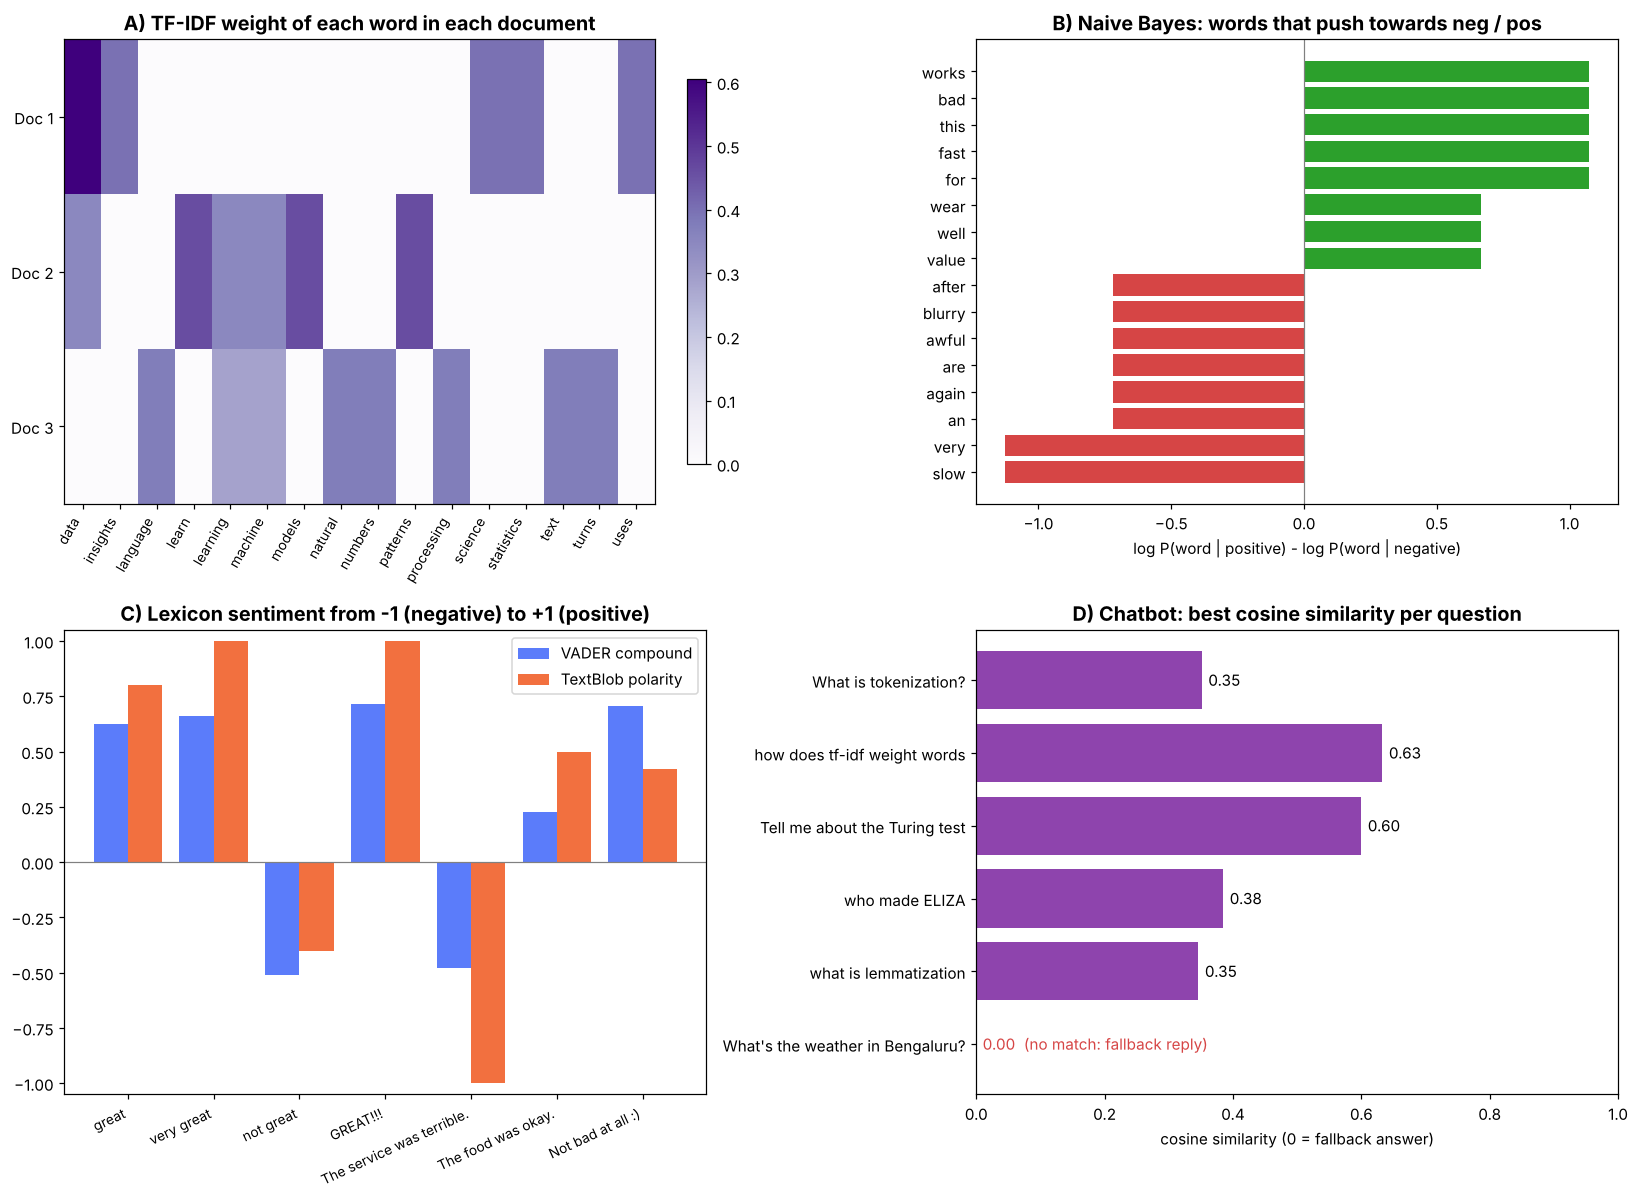

In [ ]:
from IPython.display import Image, display
display(Image("nlp_master_plot.png"))

---

💼 [LinkedIn](https://www.linkedin.com/in/prajwalskandas) · 💻 [GitHub](https://github.com/prajwalskandas31-sudo) · 🏠 [Course home](https://chipped-willow-4a2.notion.site/AI-Engineering-Course-Tech-with-Prajwal-4056f1ed006e819e88c5c3d15d1b2e0c)